Installing required libraries...

Libraries imported successfully!
TensorFlow version: 2.21.0

Project configuration completed!

Please wait. This may take some time.


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/plant_village/incomplete.HBRPOI_1.0.2/plant_village-train.tfrecord-[0-9][0…

Dataset plant_village downloaded and prepared to /root/tensorflow_datasets/plant_village/1.0.2. Subsequent calls will reuse this data.

Dataset loaded successfully!
Number of classes: 38

Preparing images...
Images prepared successfully!

Displaying sample images...


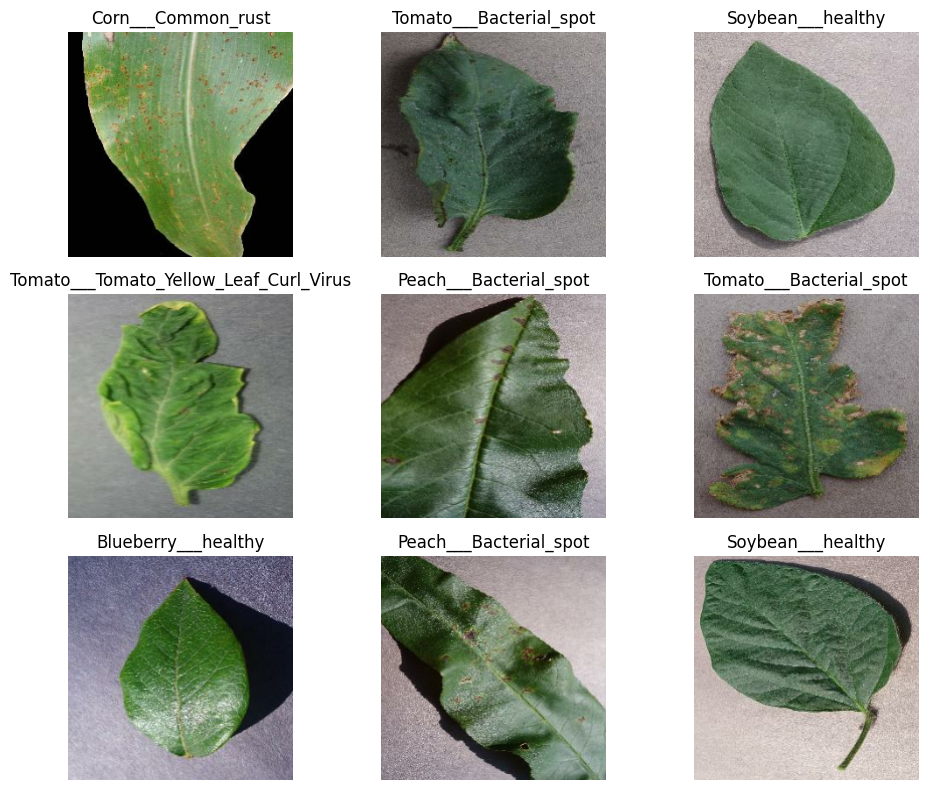


Building AI model...
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,306,662 (8.80 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


AI model created successfully!

Starting model training...
Epoch 1/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 145s 94ms/step - accuracy: 0.8426 - loss: 0.5554 - val_accuracy: 0.9295 - val_loss: 0.2377
Epoch 2/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 115s 84ms/step - accuracy: 0.9160 - loss: 0.2653 - val_accuracy: 0.9285 - val_loss: 0.2211
Epoch 3/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 113s 83ms/step - accuracy: 0.9242 - loss: 0.2333 - val_accuracy: 0.9235 - val_loss: 0.2269
Epoch 4/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 125s 91ms/step - accuracy: 0.9284 - loss: 0.2169 - val_accuracy: 0.9420 - val_loss: 0.1824
Epoch 5/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 152s 111ms/step - accuracy: 0.9301 - loss: 0.2140 - val_accuracy: 0.9422 - val_loss: 0.1834
Epoch 6/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 115s 84ms/step - accuracy: 0.9335 - loss: 0.1996 - val_accuracy: 0.9480 - val_loss: 0.1596
Epoch 7/8
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 114s 83ms/step - accuracy: 0.9346 - loss: 0.1974 - val_accuracy: 0.9455 - val_loss: 0.1644
Epoch 8/8
1358/

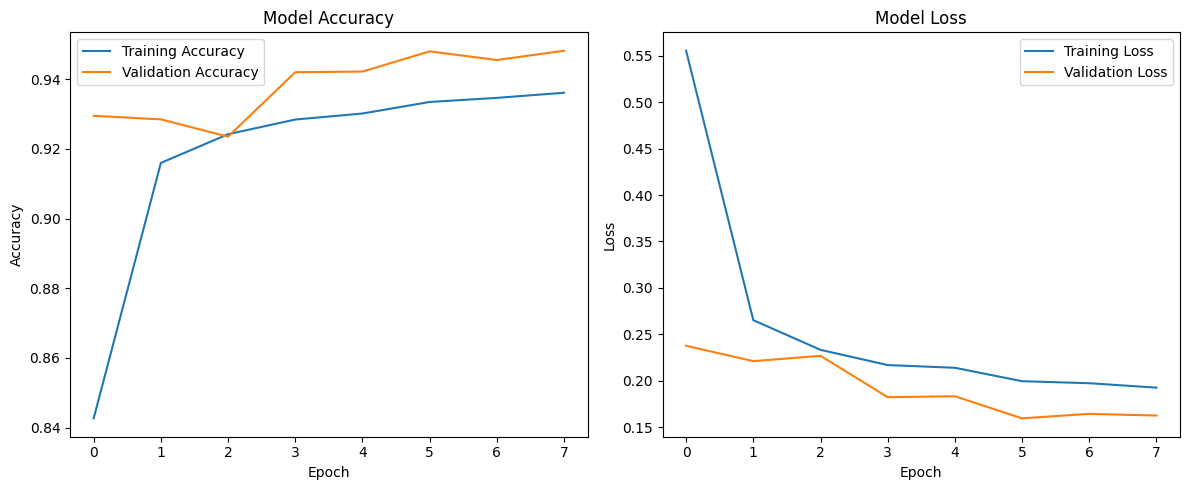


Saving trained model...
Model saved successfully!

Upload a plant leaf image to test the model.


Saving images.jpeg to images.jpeg


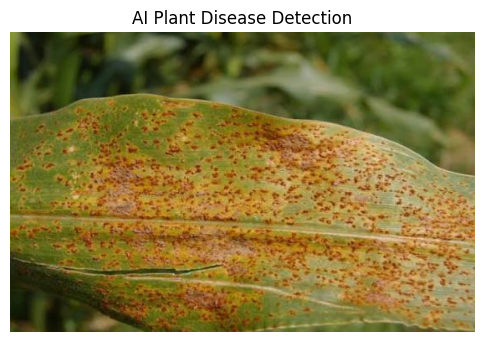


========== PREDICTION RESULT ==========
Image: images.jpeg
Predicted Class: Corn___Common_rust
Confidence: 99.73%

Note: This is an AI prediction, not a confirmed agricultural diagnosis.

Your project is ready!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


PROJECT COMPLETED SUCCESSFULLY!


In [1]:
# =====================================================
# AI PLANT DISEASE DETECTOR
# Complete Google Colab Project
# =====================================================

# 1. INSTALL LIBRARIES
import sys
import subprocess

print("Installing required libraries...")

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "tensorflow-datasets",
    "importlib-resources",
    "pillow",
    "matplotlib"
])

# 2. IMPORT LIBRARIES
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt
import json
import os

from PIL import Image
from google.colab import files
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

print("\nLibraries imported successfully!")
print("TensorFlow version:", tf.__version__)

# 3. CONFIGURATION
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 8
SEED = 42

tf.keras.utils.set_random_seed(SEED)

print("\nProject configuration completed!")

# 4. LOAD PLANTVILLAGE DATASET
print("\nDownloading PlantVillage dataset...")
print("Please wait. This may take some time.")

(train_ds, val_ds), info = tfds.load(
    "plant_village",
    split=["train[:80%]", "train[80%:]"],
    as_supervised=True,
    with_info=True,
    shuffle_files=True
)

class_names = info.features["label"].names
num_classes = len(class_names)

print("\nDataset loaded successfully!")
print("Number of classes:", num_classes)

# 5. PREPARE IMAGES
print("\nPreparing images...")

def prepare_image(image, label):
    image = tf.image.resize(
        image,
        (IMG_SIZE, IMG_SIZE)
    )
    return image, label

train_ds = train_ds.map(
    prepare_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.map(
    prepare_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_ds = (
    train_ds
    .shuffle(1000, seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = (
    val_ds
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Images prepared successfully!")

# 6. DISPLAY SAMPLE IMAGES
print("\nDisplaying sample images...")

plt.figure(figsize=(10, 8))

for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i].numpy())])
        plt.axis("off")

plt.tight_layout()
plt.show()

# 7. BUILD AI MODEL
print("\nBuilding AI model...")

augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

base_model = MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = layers.Input(
    shape=(IMG_SIZE, IMG_SIZE, 3)
)

x = augmentation(inputs)

x = layers.Rescaling(
    scale=1./127.5,
    offset=-1
)(x)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    num_classes,
    activation="softmax"
)(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

print("\nAI model created successfully!")

# 8. TRAIN THE MODEL
print("\nStarting model training...")

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

print("\nTraining completed successfully!")

# 9. EVALUATE MODEL
print("\nEvaluating model...")

loss, accuracy = model.evaluate(val_ds)

print("\n========== MODEL RESULTS ==========")
print(f"Validation Accuracy: {accuracy * 100:.2f}%")
print(f"Validation Loss: {loss:.4f}")
print("===================================")

# 10. DISPLAY TRAINING RESULTS
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

# 11. SAVE MODEL
print("\nSaving trained model...")

model.save("plant_disease_model.keras")

with open("class_names.json", "w") as f:
    json.dump(class_names, f)

print("Model saved successfully!")

# 12. UPLOAD A NEW PLANT IMAGE
print("\nUpload a plant leaf image to test the model.")

uploaded = files.upload()

# 13. PREDICT PLANT DISEASE
for filename in uploaded.keys():

    try:
        image = Image.open(filename).convert("RGB")

        resized_image = image.resize(
            (IMG_SIZE, IMG_SIZE)
        )

        img_array = np.array(
            resized_image,
            dtype=np.float32
        )

        img_array = np.expand_dims(
            img_array,
            axis=0
        )

        predictions = model.predict(
            img_array,
            verbose=0
        )

        predicted_index = int(
            np.argmax(predictions[0])
        )

        predicted_class = class_names[predicted_index]

        confidence = float(
            predictions[0][predicted_index] * 100
        )

        plt.figure(figsize=(6, 6))
        plt.imshow(image)
        plt.axis("off")
        plt.title("AI Plant Disease Detection")
        plt.show()

        print("\n========== PREDICTION RESULT ==========")
        print("Image:", filename)
        print("Predicted Class:", predicted_class)
        print(f"Confidence: {confidence:.2f}%")
        print("=======================================")

        print(
            "\nNote: This is an AI prediction, "
            "not a confirmed agricultural diagnosis."
        )

    except Exception as e:
        print("Could not process image:", str(e))

# 14. DOWNLOAD TRAINED MODEL
print("\nYour project is ready!")

files.download("plant_disease_model.keras")

print("\nPROJECT COMPLETED SUCCESSFULLY!")


In [2]:
 from google.colab import files
import json

model_path = 'plant_disease_model.keras'
model.save(model_path)
print(f"تم حفظ النموذج بنجاح في: {model_path}")

class_names_path = 'class_names.json'
with open(class_names_path, 'w') as f:
    json.dump(class_names, f)
print(f"تم حفظ أسماء الفئات في: {class_names_path}")

print("جاري بدء تنزيل ملف النموذج...")
files.download(model_path)

print("جاري بدء تنزيل أسماء الفئات...")
files.download(class_names_path)

تم حفظ النموذج بنجاح في: plant_disease_model.keras
تم حفظ أسماء الفئات في: class_names.json
جاري بدء تنزيل ملف النموذج...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

جاري بدء تنزيل أسماء الفئات...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>